In [4]:
pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv(r'C:\Users\Dell\Downloads\creditcard.csv')


# Summary statistics & missing values check
print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum().sum())
print("\nClass Distribution:")
print(df['Class'].value_counts())
print("\nClass Proportions (%):")
print(df['Class'].value_counts(normalize=True) * 100)

# Quick look at data
print(df.head())

Dataset Shape: (284807, 31)

Missing Values:
 0

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class Proportions (%):
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.90941

C:\Users\Dell\AppData\Local\Temp\ipykernel_9952\2435653579.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df_clean, palette=['#1f77b4', '#d62728'])


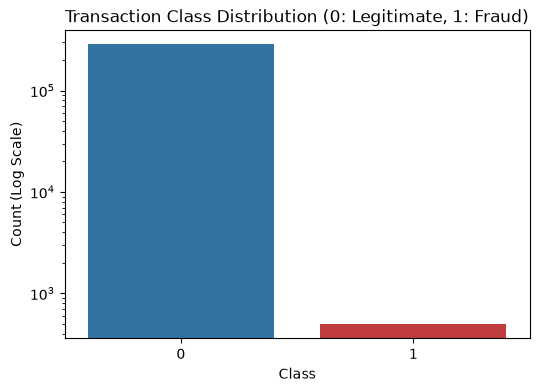

In [9]:
from sklearn.preprocessing import RobustScaler

# RobustScaler is less sensitive to extreme outliers in transaction amounts
scaler = RobustScaler()

df['scaled_amount'] = scaler.fit_transform(df[['Amount']])
df['scaled_time'] = scaler.fit_transform(df[['Time']])

# Drop original unscaled columns
df_clean = df.drop(columns=['Amount', 'Time'])

# Plot Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df_clean, palette=['#1f77b4', '#d62728'])
plt.title('Transaction Class Distribution (0: Legitimate, 1: Fraud)')
plt.yscale('log') # Log scale helps visualize the small minority class
plt.ylabel('Count (Log Scale)')
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Define X and y
X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

# Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Original Train shape: {X_train.shape}, Fraud cases: {sum(y_train == 1)}")

# Apply SMOTE only on Train data to prevent data leakage
smote = SMOTE(sampling_strategy=0.1, random_state=42) # Resample fraud to 10% of majority class
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Resampled Train shape: {X_train_res.shape}, Fraud cases: {sum(y_train_res == 1)}")

Original Train shape: (227845, 30), Fraud cases: 394
Resampled Train shape: (250196, 30), Fraud cases: 22745


In [11]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, auc

# Initialize Models
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, eval_metric='logloss')
}

# Evaluate Models
results = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_res, y_train_res)
    
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    # Calculate Precision-Recall AUC
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = auc(recall, precision)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    results[name] = model
    
    print(f"\n==================== {name} Results ====================")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print(f"ROC-AUC Score: {roc_auc:.4f}")
    print(f"PR-AUC Score: {pr_auc:.4f}")


Training Random Forest...

==================== Random Forest Results ====================
Confusion Matrix:
[[56840    24]
 [   12    86]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.78      0.88      0.83        98

    accuracy                           1.00     56962
   macro avg       0.89      0.94      0.91     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC Score: 0.9790
PR-AUC Score: 0.8638

Training XGBoost...

==================== XGBoost Results ====================
Confusion Matrix:
[[56827    37]
 [   16    82]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.69      0.84      0.76        98

    accuracy                           1.00     56962
   macro avg       0.84      0.92      0.88     56962
weighted avg       1.00      1.00      1

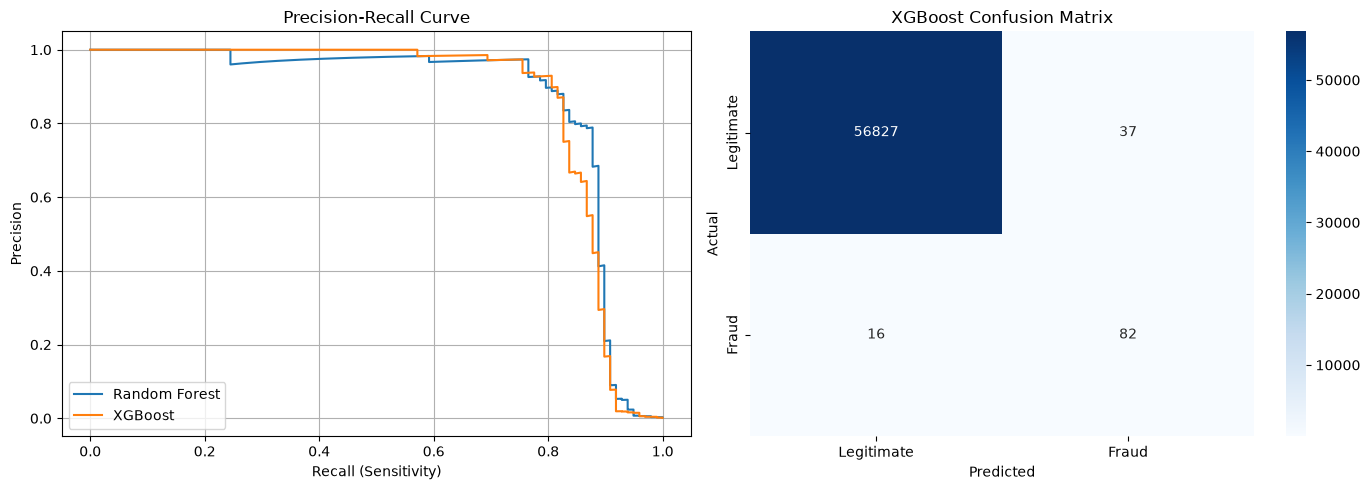

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, model in results.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    
    # PR Curve
    axes[0].plot(recall, precision, label=f'{name}')
    
axes[0].set_xlabel('Recall (Sensitivity)')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve')
axes[0].legend()
axes[0].grid(True)

# Confusion Matrix for XGBoost
y_pred_xgb = results['XGBoost'].predict(X_test)
cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud'])
axes[1].set_title('XGBoost Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

C:\Users\Dell\AppData\Local\Temp\ipykernel_9952\222882767.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')


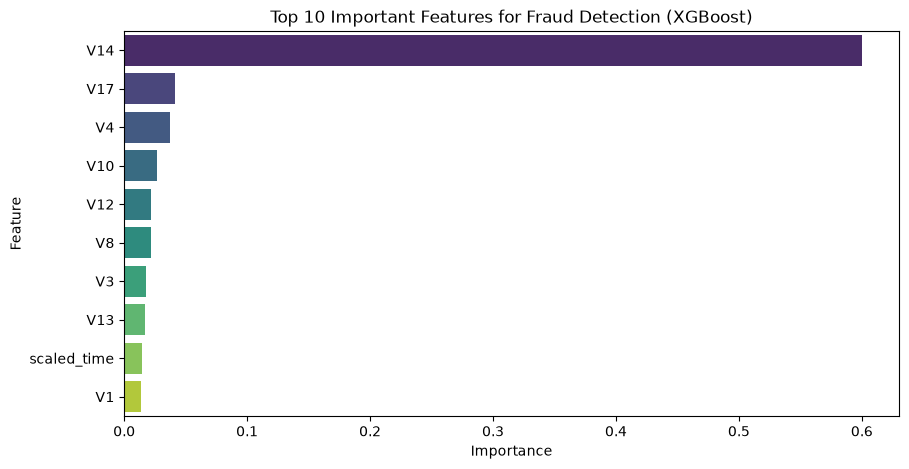

In [14]:
importances = results['XGBoost'].feature_importances_
features = X.columns

feat_imp = pd.DataFrame({'Feature': features, 'Importance': importances})
feat_imp = feat_imp.sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')
plt.title('Top 10 Important Features for Fraud Detection (XGBoost)')
plt.show()